# Поиск выбросов и генерация новых признаков

**Домашнее задание к занятию «Поиск выбросов и генерация новых признаков»**

Автор: **Александра Бужор** · Telegram: [@Angry_C_F_O](https://t.me/Angry_C_F_O)

## Задача

Решить задачу классификации типа стекла на датасете [Glass Identification](https://archive.ics.uci.edu/ml/datasets/Glass+Identification) (UCI, копия на Kaggle — *Glass Classification*). Целевая переменная — `Type`, признаки — коэффициент преломления `RI` и содержание оксидов химических элементов `Na, Mg, Al, Si, K, Ca, Ba, Fe` (вес. %). Датасет нужно исследовать на выбросы, провести EDA и сравнить качество модели до и после обработки выбросов.

| `Type` | Класс | Описание |
|---|---|---|
| 1 | building_windows_float_processed | оконное стекло зданий, флоат-процесс |
| 2 | building_windows_non_float_processed | оконное стекло зданий, не флоат |
| 3 | vehicle_windows_float_processed | автомобильные стёкла, флоат-процесс |
| 4 | vehicle_windows_non_float_processed | **в датасете отсутствует** |
| 5 | containers | тара |
| 6 | tableware | посуда |
| 7 | headlamps | фары |

## Этапы работы

1. Загрузка данных.
2. Первичный анализ: количество записей по классам, вывод.
3. Разделение выборки: 80 % — обучение, 20 % — тест.
4. Обучение `RandomForestClassifier` на обучающем множестве.
5. Предсказание на тесте и расчёт точности (accuracy).
6. Обработка выбросов: (a) визуализация распределений и проверка на нормальность; (b) поиск выбросов несколькими способами; (c) удаление выбросов и процент удалённых записей по каждому классу.
7. Повтор п. 4 и п. 5 на очищенных данных.
8. Выводы: какие преобразования сделаны, сравнение точности моделей, плюсы и минусы исследования данных на выбросы.

> **Примечание.** Функция `sns.distplot` объявлена устаревшей и будет удалена в seaborn 0.14, поэтому распределения строятся её современной заменой — `sns.histplot(..., kde=True)`. Ящики с усами — через `sns.boxplot`.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)

RANDOM_STATE = 42   # фиксируем случайность для воспроизводимости
TEST_SIZE = 0.2     # 80 % обучение / 20 % тест

In [2]:
# Единое оформление графиков: светлый фон, приглушённая сетка, фиксированный цвет у каждого класса
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, ACCENT, ALERT = "#e1e0d9", "#c3c2b7", "#2a78d6", "#e34948"

CLASS_COLORS = {"1": "#2a78d6", "2": "#eb6834", "3": "#1baf7a",
                "5": "#eda100", "6": "#e87ba4", "7": "#008300"}

SEQ_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list(
    "div_blue_red", ["#0d366b", "#2a78d6", "#9ec5f4", "#f0efec", "#f3b0af", "#e34948", "#8f2525"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "font.size": 10, "legend.frameon": False,
})

## 1. Загрузка данных

Файл `glass.csv` скачан со страницы датасета на Kaggle и лежит в папке `data/` репозитория. Если ноутбук запущен без локальной копии (например, в Google Colab), данные подгружаются напрямую из репозитория на GitHub.

In [3]:
DATA_PATH = Path("data/glass.csv")
DATA_URL = "https://raw.githubusercontent.com/AngryAlexQA/SearchGen/main/data/glass.csv"

df_raw = pd.read_csv(DATA_PATH if DATA_PATH.exists() else DATA_URL)
print(f"Размер датасета: {df_raw.shape[0]} строк × {df_raw.shape[1]} столбцов")
df_raw.head()

Размер датасета: 214 строк × 10 столбцов


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.521,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.518,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.516,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.518,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.517,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


## 2. Первичный анализ

In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [5]:
print("Пропусков в данных:", df_raw.isna().sum().sum())
print("Полных дубликатов: ", df_raw.duplicated().sum())
df_raw[df_raw.duplicated(keep=False)]

Пропусков в данных: 0
Полных дубликатов:  1


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
38,1.522,14.21,3.82,0.47,71.77,0.11,9.57,0.0,0.0,1
39,1.522,14.21,3.82,0.47,71.77,0.11,9.57,0.0,0.0,1


Пропусков нет, все признаки числовые. Найден **один полный дубликат** (строки 38 и 39, класс 1). Удаляем его до разбиения выборки: иначе одна и та же запись может оказаться и в обучении, и в тесте и искусственно завысить точность.

In [6]:
df = df_raw.drop_duplicates().reset_index(drop=True)

TARGET = "Type"
FEATURES = [c for c in df.columns if c != TARGET]
print(f"После удаления дубликата: {len(df)} записей, {len(FEATURES)} признаков")

df[FEATURES].describe().T

После удаления дубликата: 213 записей, 9 признаков


,count,mean,std,min,25%,50%,75%,max
RI,213.0,1.518,0.003,1.511,1.517,1.518,1.519,1.534
Na,213.0,13.404,0.817,10.730,12.900,13.300,13.810,17.380
Mg,213.0,2.679,1.444,0.000,2.090,3.480,3.600,4.490
Al,213.0,1.449,0.496,0.290,1.190,1.360,1.630,3.500
Si,213.0,72.655,0.774,69.810,72.280,72.790,73.090,75.410
K,213.0,0.499,0.653,0.000,0.130,0.560,0.610,6.210
Ca,213.0,8.954,1.426,5.430,8.240,8.600,9.150,16.190
Ba,213.0,0.176,0.498,0.000,0.000,0.000,0.000,3.150
Fe,213.0,0.057,0.098,0.000,0.000,0.000,0.100,0.510


### 2a. Количество записей для каждого класса

In [7]:
CLASS_NAMES = {1: "окна зданий, float", 2: "окна зданий, non-float", 3: "окна авто, float",
               5: "тара", 6: "посуда", 7: "фары"}
CLASS_SHORT = {1: "окна зданий\nfloat", 2: "окна зданий\nnon-float", 3: "окна авто\nfloat",
               5: "тара", 6: "посуда", 7: "фары"}

counts = df[TARGET].value_counts().sort_index()
class_table = pd.DataFrame({
    "Описание": counts.index.map(CLASS_NAMES),
    "Записей": counts.values,
    "Доля, %": (counts / counts.sum() * 100).round(1).values,
}, index=counts.index.rename("Type"))
class_table

,Описание,Записей,"Доля, %"
Type,,,
1,"окна зданий, float",69,32.4
2,"окна зданий, non-float",76,35.7
3,"окна авто, float",17,8.0
5,тара,13,6.1
6,посуда,9,4.2
7,фары,29,13.6


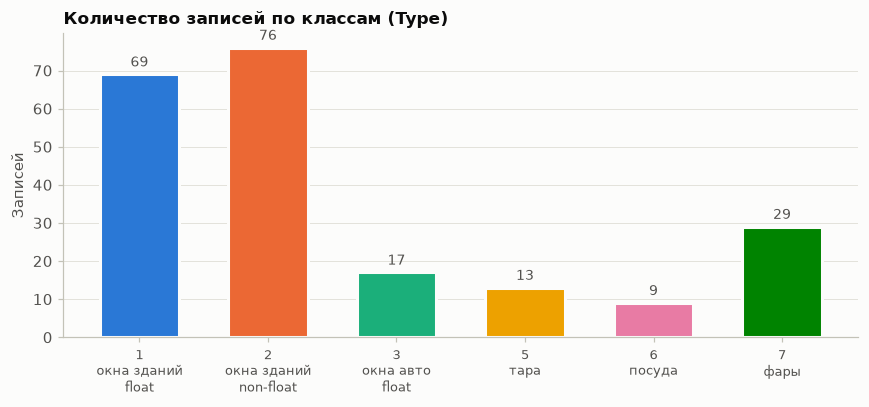

Самый крупный класс больше самого маленького в 8.4 раза


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
labels = [f"{t}\n{CLASS_SHORT[t]}" for t in counts.index]
bars = ax.bar(labels, counts.values, width=0.62,
              color=[CLASS_COLORS[str(t)] for t in counts.index], edgecolor=SURFACE, linewidth=2)
ax.bar_label(bars, padding=3, color=INK_2, fontsize=9)
ax.set_title("Количество записей по классам (Type)")
ax.set_ylabel("Записей")
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", labelsize=8.5)
plt.tight_layout()
plt.show()

print(f"Самый крупный класс больше самого маленького в {counts.max() / counts.min():.1f} раза")

**Вывод по количеству записей в классах:**

- В данных **6 классов из 7** описанных: класса 4 (автомобильные стёкла, не флоат) нет.
- **Сильный дисбаланс**: два класса оконного стекла зданий (1 и 2) — 145 из 213 записей (68 %); самые малочисленные — посуда (9 записей, 4.2 %) и тара (13 записей, 6.1 %). Крупнейший класс больше наименьшего в 8.4 раза.
- Что из этого следует для работы:
  1. разбиение на train/test делаем **стратифицированным**;
  2. в тест попадёт лишь 2–3 записи редких классов, а одна ошибка на тесте из 43 записей меняет accuracy на 2.3 п.п. — поэтому дополнительно смотрим balanced accuracy и macro-F1 и проверяем выводы кросс-валидацией;
  3. при поиске выбросов важно не «вычистить» редкие классы: на фоне большинства любая запись редкого класса выглядит аномальной.

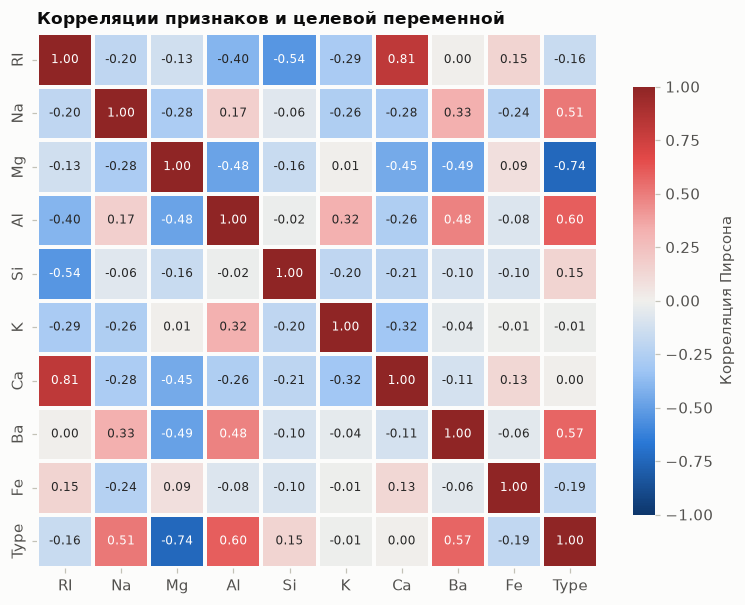

In [9]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(7, 5.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIV_CMAP, vmin=-1, vmax=1, center=0,
            linewidths=1.5, linecolor=SURFACE, annot_kws={"size": 8},
            cbar_kws={"shrink": 0.8, "label": "Корреляция Пирсона"}, ax=ax)
ax.set_title("Корреляции признаков и целевой переменной")
plt.tight_layout()
plt.show()

**По корреляциям:**

- `RI` сильно связан с `Ca` (0.81) и отрицательно — с `Si` (−0.54): коэффициент преломления определяется химическим составом стекла.
- С целевой переменной сильнее всего связаны `Mg` (−0.74), `Al` (0.60), `Ba` (0.57) и `Na` (0.51). `Type` — номинальная переменная, поэтому корреляция с ней лишь ориентир: эти оксиды отличают оконное стекло (классы 1–3) от неоконного (5–7).
- `Mg` отрицательно связан с `Al`, `Ba` и `Ca` (около −0.45…−0.49).

## 3. Разделение на обучающее и тестовое множества

80 % данных — обучение, 20 % — тест. Используем стратификацию по `Type`, чтобы редкие классы (посуда — 9 записей, тара — 13) попали в обе части в тех же пропорциях. **Тестовое множество фиксируется один раз** и используется для оценки обеих моделей — только так их точность можно сравнивать напрямую.

In [10]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

split_table = pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}).sort_index()
split_table.loc["Итого"] = split_table.sum()
print(f"Обучение: {len(X_train)} записей, тест: {len(X_test)} записей")
split_table

Обучение: 170 записей, тест: 43 записей


,train,test
Type,,
1,55,14
2,61,15
3,14,3
5,10,3
6,7,2
7,23,6
Итого,170,43


## 4. Модель 1: `RandomForestClassifier` на исходных данных

Гиперпараметры по умолчанию (100 деревьев, критерий Gini), фиксирован только `random_state`. Задача работы — оценить влияние обработки данных, а не подбор параметров, поэтому модель в обоих экспериментах одна и та же.

In [11]:
def make_model():
    # Одинаковая конфигурация случайного леса для всех экспериментов
    return RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)


def evaluate(model, X_eval, y_eval):
    # Accuracy + метрики, учитывающие дисбаланс классов
    pred = model.predict(X_eval)
    metrics = {
        "accuracy": accuracy_score(y_eval, pred),
        "balanced_accuracy": balanced_accuracy_score(y_eval, pred),
        "f1_macro": f1_score(y_eval, pred, average="macro"),
    }
    return metrics, pred


model_base = make_model().fit(X_train, y_train)

## 5. Предсказание на тесте и точность модели 1

Кроме обязательной accuracy выводим balanced accuracy и macro-F1: при сильном дисбалансе классов accuracy может быть высокой даже при плохом распознавании редких классов.

In [12]:
metrics_base, pred_base = evaluate(model_base, X_test, y_test)

print(f"Accuracy модели 1 на тесте: {metrics_base['accuracy']:.4f}  "
      f"({(pred_base == y_test).sum()} из {len(y_test)} верно)")
print(f"Balanced accuracy: {metrics_base['balanced_accuracy']:.4f} | macro-F1: {metrics_base['f1_macro']:.4f}\n")
print(classification_report(y_test, pred_base, digits=3, zero_division=0))

Accuracy модели 1 на тесте: 0.8605  (37 из 43 верно)
Balanced accuracy: 0.8437 | macro-F1: 0.8318

              precision    recall  f1-score   support

           1      0.867     0.929     0.897        14
           2      0.857     0.800     0.828        15
           3      1.000     0.667     0.800         3
           5      0.667     0.667     0.667         3
           6      0.667     1.000     0.800         2
           7      1.000     1.000     1.000         6

    accuracy                          0.860        43
   macro avg      0.843     0.844     0.832        43
weighted avg      0.868     0.860     0.860        43



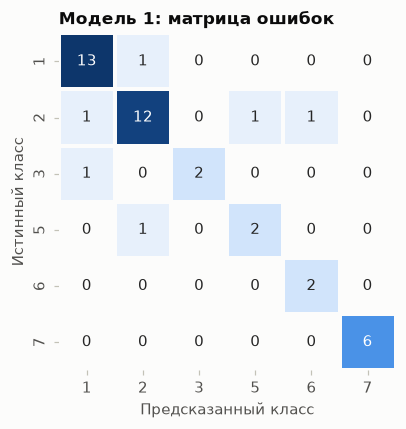

In [13]:
def plot_confusion(ax, y_true, y_pred, title):
    labels = sorted(y_true.unique())
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap=SEQ_CMAP, cbar=False, square=True,
                linewidths=1.5, linecolor=SURFACE, xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
    ax.grid(False)


fig, ax = plt.subplots(figsize=(4.4, 4))
plot_confusion(ax, y_test, pred_base, "Модель 1: матрица ошибок")
plt.tight_layout()
plt.show()

**Итог модели 1:** accuracy = **0.8605** (37 из 43 верно), balanced accuracy 0.8437, macro-F1 0.8318. Фары (7) и посуда (6) распознаются без пропусков; основная путаница — между двумя классами оконного стекла зданий (1 ↔ 2), плюс единичные ошибки на автомобильных стёклах (3) и таре (5).

## 6. Обработка выбросов

### 6a. Визуализация распределений

Ящики с усами (`sns.boxplot`) показывают медиану, квартили и точки за пределами усов `1.5·IQR` — кандидатов в выбросы по правилу Тьюки. Гистограммы с оценкой плотности (`sns.histplot(kde=True)` вместо устаревшего `distplot`) показывают форму распределения.

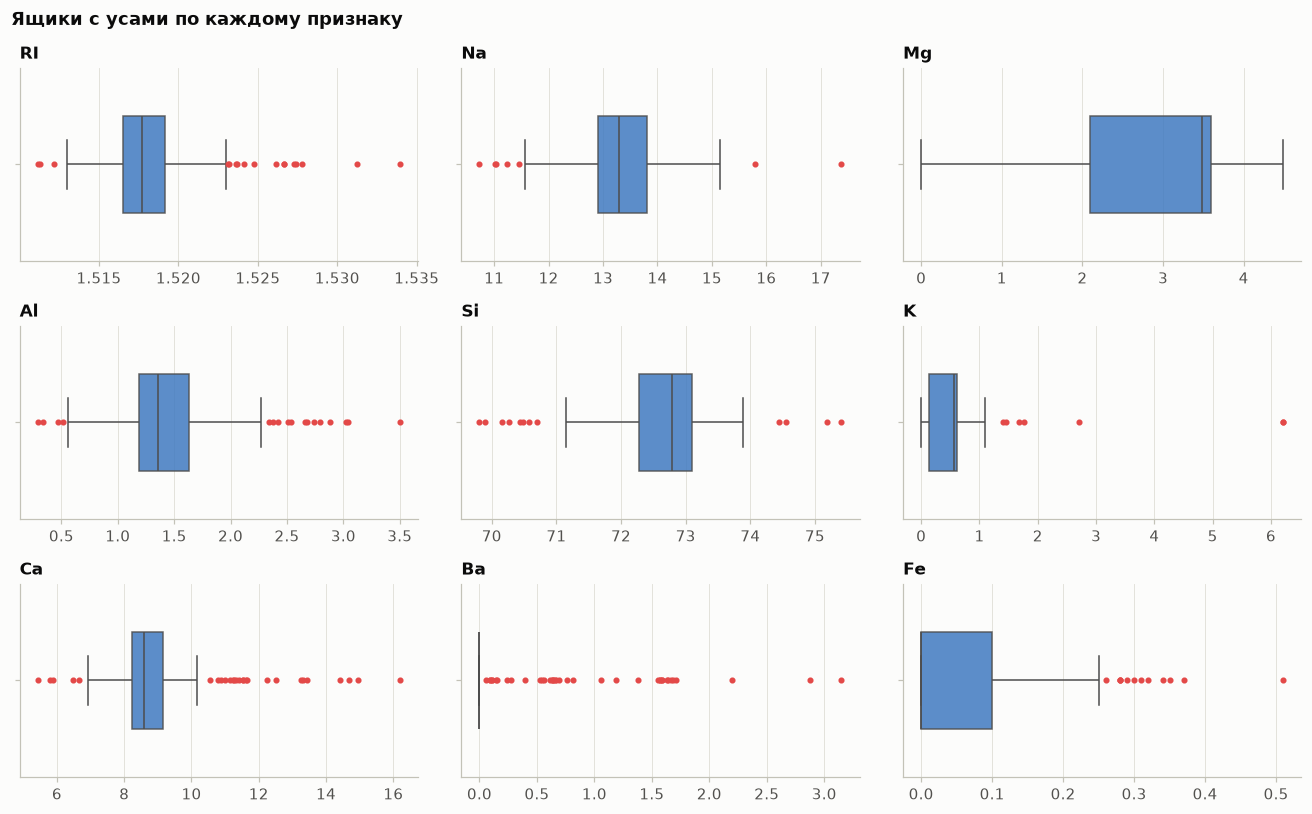

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(12, 7.5))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(x=df[col], ax=ax, color=ACCENT, width=0.5, linewidth=1, fliersize=3,
                boxprops={"alpha": 0.85}, flierprops={"markerfacecolor": ALERT, "markeredgecolor": ALERT})
    ax.set_title(col)
    ax.set_xlabel("")
    ax.grid(axis="y", visible=False)
fig.suptitle("Ящики с усами по каждому признаку", x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

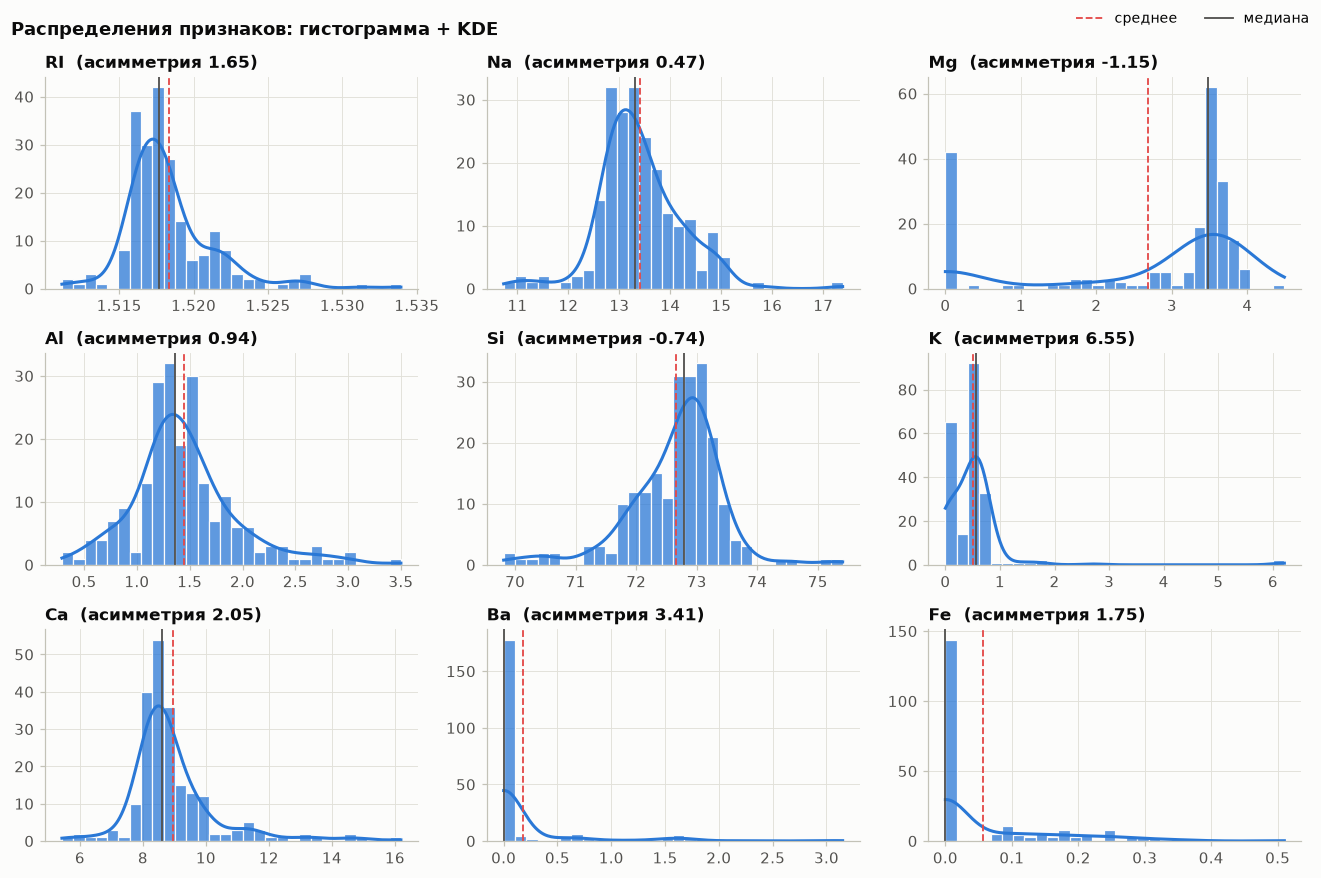

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color=ACCENT, edgecolor=SURFACE, linewidth=0.8,
                 alpha=0.75, line_kws={"linewidth": 2})
    ax.axvline(df[col].mean(), color=ALERT, linewidth=1.2, linestyle="--", label="среднее")
    ax.axvline(df[col].median(), color=INK_2, linewidth=1.2, label="медиана")
    ax.set_title(f"{col}  (асимметрия {df[col].skew():.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("")
handles, labels_ = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="upper right", ncol=2, fontsize=9)
fig.suptitle("Распределения признаков: гистограмма + KDE", x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

**Есть ли признаки с нормальным распределением?** Проверим формально: тест Шапиро–Уилка и тест Д'Агостино–Пирсона (нулевая гипотеза — распределение нормальное, уровень значимости α = 0.05), а также асимметрию, эксцесс и долю нулевых значений.

In [16]:
ALPHA = 0.05
rows = []
for col in FEATURES:
    x = df[col]
    sh = stats.shapiro(x)
    dp = stats.normaltest(x)
    rows.append({
        "признак": col,
        "асимметрия": x.skew(),
        "эксцесс": x.kurt(),
        "доля нулей, %": (x == 0).mean() * 100,
        "Shapiro W": sh.statistic,
        "Shapiro p": sh.pvalue,
        "D'Agostino p": dp.pvalue,
        "нормальное?": "да" if min(sh.pvalue, dp.pvalue) > ALPHA else "нет",
    })
normality = pd.DataFrame(rows).set_index("признак")
normality.style.format({"асимметрия": "{:.2f}", "эксцесс": "{:.2f}", "доля нулей, %": "{:.1f}",
                        "Shapiro W": "{:.3f}", "Shapiro p": "{:.1e}", "D'Agostino p": "{:.1e}"})

,асимметрия,эксцесс,"доля нулей, %",Shapiro W,Shapiro p,D'Agostino p,нормальное?
признак,,,,,,,
RI,1.65,5.04,0.0,0.865,8.4e-13,2.7e-19,нет
Na,0.47,3.08,0.0,0.945,2.9e-07,1.1e-06,нет
Mg,-1.15,-0.43,19.7,0.700,2.8e-19,1.8e-08,нет
Al,0.94,2.12,0.0,0.942,1.5e-07,4.8e-09,нет
Si,-0.74,3.02,0.0,0.918,1.7e-09,1.1e-08,нет
K,6.55,54.54,14.1,0.441,2.4e-25,8.6e-67,нет
Ca,2.05,6.67,0.0,0.792,4.1e-16,2.0e-24,нет
Ba,3.41,12.46,82.2,0.410,6.4e-26,5.8e-39,нет
Fe,1.75,2.63,67.1,0.655,1.4e-20,3.0e-17,нет


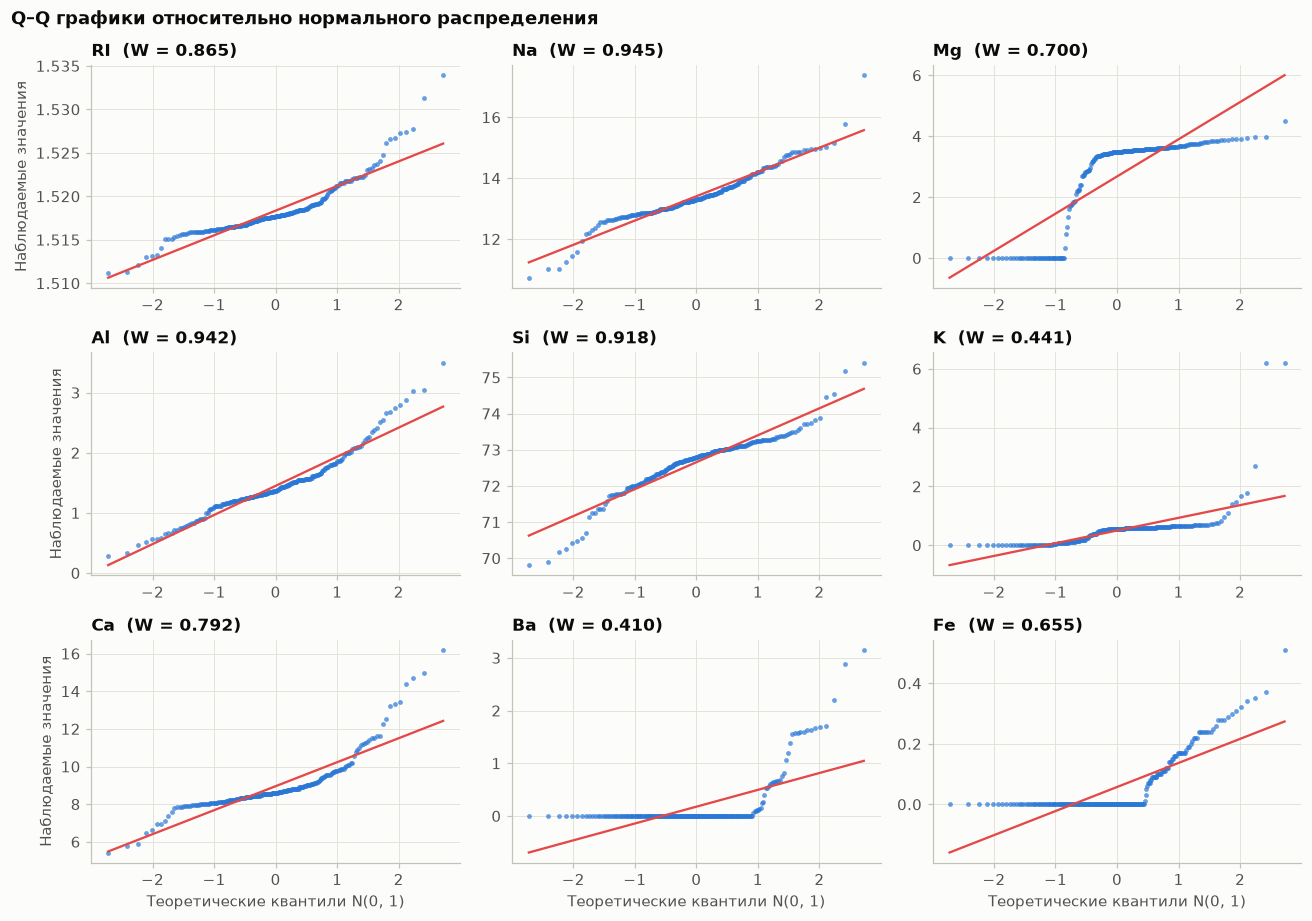

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8.5))
for ax, col in zip(axes.flat, FEATURES):
    (osm, osr), (slope, intercept, _) = stats.probplot(df[col], dist="norm")
    ax.scatter(osm, osr, s=10, color=ACCENT, alpha=0.7, linewidths=0)
    ax.plot(osm, slope * np.asarray(osm) + intercept, color=ALERT, linewidth=1.5)
    ax.set_title(f"{col}  (W = {normality.loc[col, 'Shapiro W']:.3f})")
for ax in axes[-1]:
    ax.set_xlabel("Теоретические квантили N(0, 1)")
for ax in axes[:, 0]:
    ax.set_ylabel("Наблюдаемые значения")
fig.suptitle("Q–Q графики относительно нормального распределения", x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

**Есть ли признаки с нормальным распределением?** Строго нормальных признаков **нет**: оба теста отвергают нормальность для всех девяти признаков (наибольшее p-value — 1.1·10⁻⁶ при α = 0.05).

- **Ближе всего к нормальному** — `Na` (W = 0.945, асимметрия 0.47), `Al` (W = 0.942) и `Si` (W = 0.918): колоколообразная одновершинная форма, но «тяжёлые» хвосты (эксцесс 2–3) — на Q–Q графиках точки уходят от прямой на краях.
- `RI` и `Ca` — одновершинные, но с выраженной правосторонней асимметрией (1.65 и 2.05) и длинным правым хвостом.
- `Mg` — **бимодальный**: 20 % нулей и основная масса значений около 3.5.
- `K`, `Ba`, `Fe` — сильно скошенные распределения с **избытком нулей** (`Ba` = 0 у 82 % записей, `Fe` = 0 у 67 %); у `K` эксцесс 54.5 из-за двух записей тары с `K` = 6.21.

Практическое следствие: правило 3σ, которое предполагает нормальность, здесь применимо лишь условно, а правило IQR для признаков с избытком нулей вырождается.

Посмотрим на те же признаки **в разрезе классов** — это важно для понимания, что именно методы поиска выбросов будут считать «выбросом».

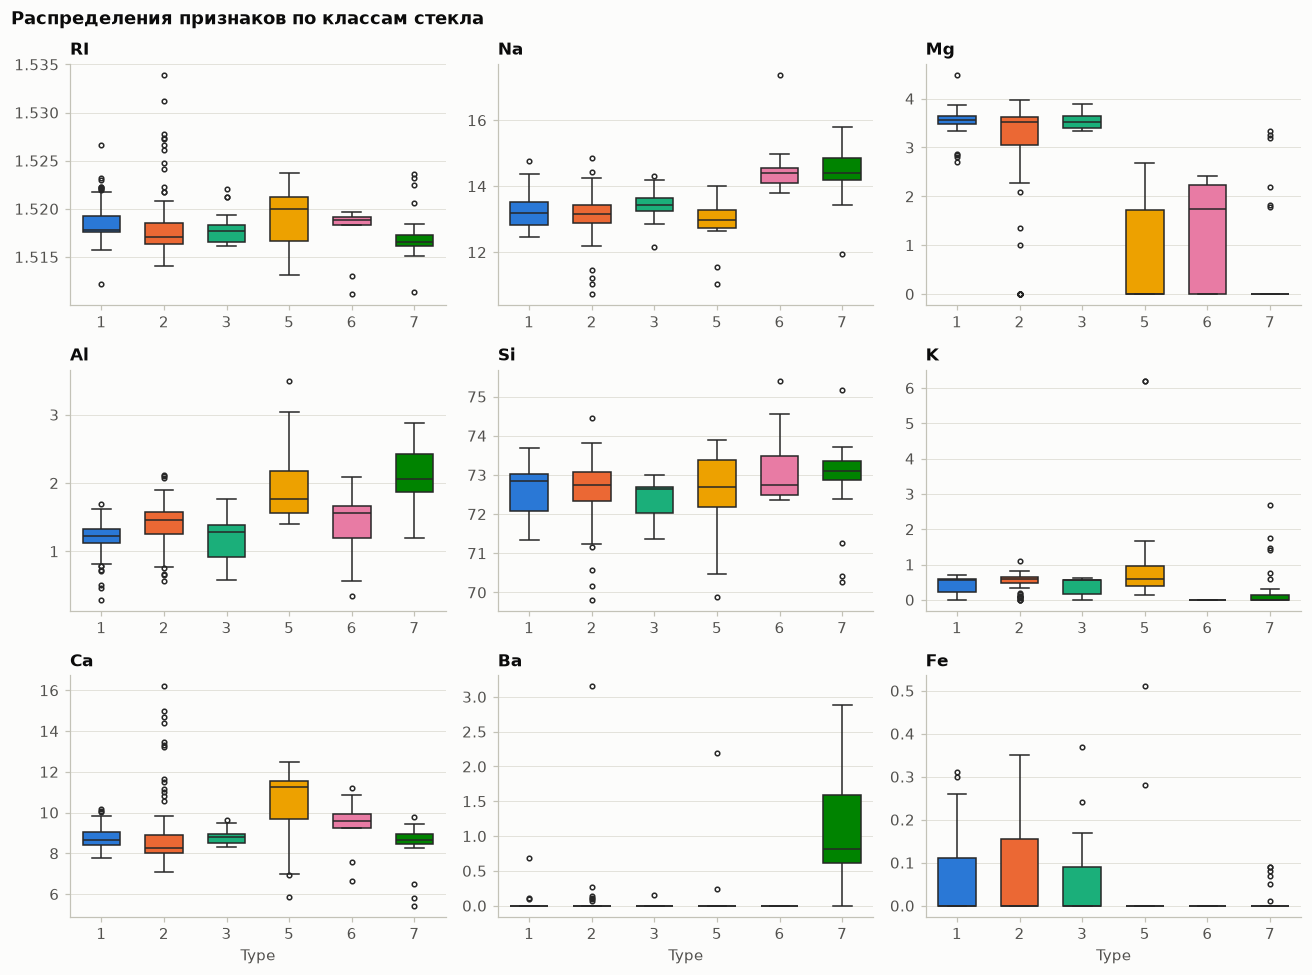

In [18]:
df_plot = df.assign(Type=df[TARGET].astype(str))
order = sorted(df_plot["Type"].unique(), key=int)

fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(data=df_plot, x="Type", y=col, hue="Type", order=order, hue_order=order,
                palette=CLASS_COLORS, legend=False, saturation=1, width=0.6, linewidth=1, fliersize=3, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(axis="x", visible=False)
for ax in axes[-1]:
    ax.set_xlabel("Type")
fig.suptitle("Распределения признаков по классам стекла", x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

**Что видно в разрезе классов:**

- Многие точки, которые на общих ящиках с усами выглядят выбросами, — **типичные значения для редких классов**: барий (`Ba`) практически есть только в фарах (7); у тары и фар магния (`Mg`) почти нет (медиана 0), тогда как у оконного стекла его около 3.5 %; у тары повышены `Al` и `Ca`, у посуды и фар — `Na`.
- Значит, «выброс» относительно всего датасета часто означает просто «запись редкого класса». Удалив такие точки, мы лишим модель самых информативных примеров.
- Внутри классов тоже есть по-настоящему нетипичные записи: например, стекло зданий non-float (класс 2) с `Ca` > 13 % и нулевым `Mg` или две записи тары с `K` = 6.21.

### 6b. Поиск выбросов несколькими способами

Сравниваем пять подходов — одномерные статистические правила и многомерные алгоритмы:

| № | Метод | Как определяется выброс | Ограничения |
|---|---|---|---|
| 1 | **IQR (правило Тьюки)** | значение признака вне `[Q1 − 1.5·IQR; Q3 + 1.5·IQR]` хотя бы по одному признаку | одномерный; при IQR = 0 (много нулей) выбросом становится любое ненулевое значение |
| 2 | **Z-оценка (правило 3σ)** | `abs(x − μ) / σ > 3` хотя бы по одному признаку | предполагает нормальность, а её нет; сами выбросы смещают μ и σ |
| 3 | **Isolation Forest** | запись, которую случайные деревья изолируют за малое число разбиений | нужно задать долю выбросов `contamination` |
| 4 | **Local Outlier Factor** | плотность вокруг точки заметно ниже, чем у её соседей (на стандартизованных признаках) | чувствителен к масштабу и `n_neighbors` |
| 5 | **Isolation Forest внутри класса** | запись нетипична **для своего класса** | на маленьких классах оценка грубее |

Для многомерных методов доля выбросов `contamination = 5 %` — консервативный бюджет (правило 3σ помечает около 9 % записей).

In [19]:
CONTAMINATION = 0.05


def iqr_bounds(X, k=1.5):
    q1, q3 = X.quantile(0.25), X.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def outliers_iqr(X, y=None, k=1.5):
    low, high = iqr_bounds(X, k)
    return ((X < low) | (X > high)).any(axis=1).to_numpy()


def outliers_zscore(X, y=None, threshold=3.0):
    z = (X - X.mean()) / X.std(ddof=0)
    return (z.abs() > threshold).any(axis=1).to_numpy()


def outliers_iforest(X, y=None, contamination=CONTAMINATION):
    iso = IsolationForest(n_estimators=300, contamination=contamination, random_state=RANDOM_STATE)
    return iso.fit_predict(X) == -1


def outliers_lof(X, y=None, contamination=CONTAMINATION, n_neighbors=20):
    X_scaled = StandardScaler().fit_transform(X)
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    return lof.fit_predict(X_scaled) == -1


def outliers_iforest_by_class(X, y, contamination=CONTAMINATION):
    # Isolation Forest обучается отдельно на записях каждого класса
    mask = np.zeros(len(X), dtype=bool)
    y_arr = np.asarray(y)
    for cls in np.unique(y_arr):
        idx = np.flatnonzero(y_arr == cls)
        iso = IsolationForest(n_estimators=300, contamination=contamination, random_state=RANDOM_STATE)
        mask[idx] = iso.fit_predict(X.iloc[idx]) == -1
    return mask


METHODS = {
    "IQR (1.5·IQR)": outliers_iqr,
    "Z-оценка (|z| > 3)": outliers_zscore,
    "Isolation Forest": outliers_iforest,
    "LOF": outliers_lof,
    "Isolation Forest по классам": outliers_iforest_by_class,
}

**Одномерные методы — по каждому признаку.** Сколько значений каждого признака выходит за границы:

In [20]:
low, high = iqr_bounds(X)
z = (X - X.mean()) / X.std(ddof=0)
per_feature = pd.DataFrame({
    "Q1": X.quantile(0.25), "Q3": X.quantile(0.75),
    "нижняя граница IQR": low, "верхняя граница IQR": high,
    "выбросов по IQR": ((X < low) | (X > high)).sum(),
    "выбросов по |z| > 3": (z.abs() > 3).sum(),
})
per_feature

,Q1,Q3,нижняя граница IQR,верхняя граница IQR,выбросов по IQR,выбросов по |z| > 3
RI,1.517,1.519,1.513,1.523,17,3
Na,12.900,13.810,11.535,15.175,7,2
Mg,2.090,3.600,-0.175,5.865,0,0
Al,1.190,1.630,0.530,2.290,17,3
Si,72.280,73.090,71.065,74.305,12,6
K,0.130,0.610,-0.590,1.330,7,3
Ca,8.240,9.150,6.875,10.515,27,7
Ba,0.000,0.000,0.000,0.000,38,6
Fe,0.000,0.100,-0.150,0.250,12,3


- У `Ba` первый и третий квартили равны нулю, IQR = 0, поэтому **любое ненулевое значение бария** считается выбросом: это 38 записей, из них 26 — фары (из 29). Похожая ситуация у `Fe` (верхняя граница 0.25).
- У `Mg` по IQR выбросов нет: 20 % нулей «растягивают» нижний ус до нуля.
- Больше всего выбросов по IQR у `Ca` (27) — это в основном классы 2 и 5 с высоким содержанием кальция.
- Правило |z| > 3 гораздо мягче (0–7 значений на признак), но опирается на нормальность, которой в данных нет.

**Все методы на полном датасете** — сколько записей помечено и какой процент записей **каждого класса** пришлось бы удалить:

In [21]:
flags = pd.DataFrame({name: fn(X, y) for name, fn in METHODS.items()}, index=X.index)

summary = pd.DataFrame({
    "записей помечено": flags.sum(),
    "% от датасета": flags.mean() * 100,
})
summary.style.format({"% от датасета": "{:.1f}"})

,записей помечено,% от датасета
IQR (1.5·IQR),78,36.6
Z-оценка (|z| > 3),20,9.4
Isolation Forest,11,5.2
LOF,11,5.2
Isolation Forest по классам,13,6.1


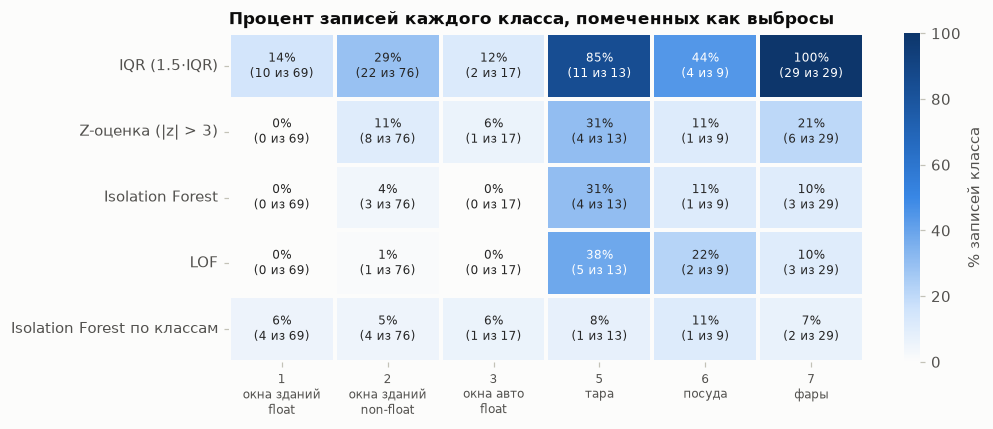

Type,1,2,3,5,6,7
IQR (1.5·IQR),14.5,28.9,11.8,84.6,44.4,100.0
Z-оценка (|z| > 3),0.0,10.5,5.9,30.8,11.1,20.7
Isolation Forest,0.0,3.9,0.0,30.8,11.1,10.3
LOF,0.0,1.3,0.0,38.5,22.2,10.3
Isolation Forest по классам,5.8,5.3,5.9,7.7,11.1,6.9


In [22]:
class_total = y.value_counts().sort_index()
removed_by_class = flags.groupby(y).sum().T            # методы × классы, количество
removed_pct = removed_by_class.div(class_total, axis=1) * 100

fig, ax = plt.subplots(figsize=(9.5, 4))
annot = removed_pct.round(0).astype(int).astype(str) + "%\n(" + removed_by_class.astype(str) + \
        " из " + class_total.reindex(removed_pct.columns).astype(str).values + ")"
sns.heatmap(removed_pct, annot=annot, fmt="", cmap=SEQ_CMAP, vmin=0, vmax=100, linewidths=1.5,
            linecolor=SURFACE, annot_kws={"size": 8}, cbar_kws={"label": "% записей класса"}, ax=ax)
ax.set_xticklabels([f"{c}\n{CLASS_SHORT[c]}" for c in removed_pct.columns], rotation=0, fontsize=8)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Процент записей каждого класса, помеченных как выбросы")
ax.grid(False)
plt.tight_layout()
plt.show()

removed_pct.round(1)

In [23]:
# Насколько методы согласны между собой: сколько методов пометили каждую запись
votes = flags.sum(axis=1)
agreement = votes.value_counts().sort_index().rename_axis("методов пометили запись").to_frame("записей")
agreement.T

методов пометили запись,0,1,2,3,4,5
записей,132,53,15,4,7,2


**Вывод по методам поиска выбросов:**

- **IQR** помечает 78 записей (36.6 % датасета), в том числе **100 % фар** и 85 % тары. Применять его «в лоб» ко всему датасету нельзя: он принимает редкий класс за аномалию.
- **Z-оценка** (20 записей, 9.4 %) и глобальные многомерные методы **Isolation Forest** и **LOF** (по 11 записей, 5.2 %) мягче, но тоже бьют в основном по редким классам: у тары помечено 31–38 % записей, у посуды 11–22 %, а у окон зданий float — 0 %.
- **Isolation Forest внутри класса** — единственный способ, который помечает сопоставимую долю каждого класса (5–11 %), то есть ищет записи, нетипичные для своего класса, а не сам редкий класс.
- Методы слабо согласованы: 132 записи не помечены ни одним методом, 53 — только одним, и лишь 2 — всеми пятью. «Выброс» — не объективное свойство записи, а результат выбора метода и порога.

### 6c. Удаление выбросов

**Выбранный способ — Isolation Forest внутри каждого класса** (5 % самых нетипичных записей класса). Он удаляет одинаковую долю из каждого класса и не уничтожает редкие классы целиком, в отличие от IQR.

**Выбросы удаляются только из обучающего множества.** Тестовая выборка имитирует новые данные, которые модель встретит на практике: «неудобные» объекты из потока реальных данных удалить нельзя. Кроме того, детектор выбросов (квантили, деревья) должен обучаться только на train — иначе информация из теста протечёт в обучение. Тест остаётся тем же, что и для модели 1.

In [24]:
X_train_r = X_train.reset_index(drop=True)
y_train_r = y_train.reset_index(drop=True)

train_outliers = outliers_iforest_by_class(X_train_r, y_train_r)
X_train_clean = X_train_r[~train_outliers]
y_train_clean = y_train_r[~train_outliers]

removal_table = pd.DataFrame({
    "Описание": [CLASS_NAMES[c] for c in class_total.index],
    "весь датасет: записей": class_total.values,
    "весь датасет: выбросов": removed_by_class.loc["Isolation Forest по классам"].values,
    "train: записей": y_train_r.value_counts().reindex(class_total.index).values,
    "train: удалено": y_train_r[train_outliers].value_counts().reindex(class_total.index, fill_value=0).values,
}, index=class_total.index.rename("Type"))
removal_table["весь датасет: % выбросов"] = removal_table["весь датасет: выбросов"] / removal_table["весь датасет: записей"] * 100
removal_table["train: % удалено"] = removal_table["train: удалено"] / removal_table["train: записей"] * 100
removal_table.loc["Итого"] = ["—"] + removal_table.drop(columns="Описание").sum().tolist()
removal_table.loc["Итого", "весь датасет: % выбросов"] = (removal_table.loc["Итого", "весь датасет: выбросов"]
                                                       / removal_table.loc["Итого", "весь датасет: записей"] * 100)
removal_table.loc["Итого", "train: % удалено"] = (removal_table.loc["Итого", "train: удалено"]
                                                 / removal_table.loc["Итого", "train: записей"] * 100)
removal_table = removal_table[["Описание", "весь датасет: записей", "весь датасет: выбросов", "весь датасет: % выбросов",
                               "train: записей", "train: удалено", "train: % удалено"]]

print(f"Обучающее множество: было {len(X_train_r)}, удалено {train_outliers.sum()}, осталось {len(X_train_clean)}")
removal_table.style.format({"весь датасет: % выбросов": "{:.1f}", "train: % удалено": "{:.1f}",
                            "весь датасет: записей": "{:.0f}", "весь датасет: выбросов": "{:.0f}",
                            "train: записей": "{:.0f}", "train: удалено": "{:.0f}"})

Обучающее множество: было 170, удалено 11, осталось 159


,Описание,весь датасет: записей,весь датасет: выбросов,весь датасет: % выбросов,train: записей,train: удалено,train: % удалено
Type,,,,,,,
1,"окна зданий, float",69,4,5.8,55,3,5.5
2,"окна зданий, non-float",76,4,5.3,61,3,4.9
3,"окна авто, float",17,1,5.9,14,1,7.1
5,тара,13,1,7.7,10,1,10.0
6,посуда,9,1,11.1,7,1,14.3
7,фары,29,2,6.9,23,2,8.7
Итого,—,213,13,6.1,170,11,6.5


In [25]:
# Какие записи удалены из обучения
removed_rows = X_train_r[train_outliers].assign(Type=y_train_r[train_outliers]).sort_values("Type")
removed_rows

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
11,1.518,12.45,2.71,1.29,73.70,0.56,9.06,0.00,0.24,1
113,1.527,13.99,3.70,0.71,71.57,0.02,9.82,0.00,0.10,1
137,1.519,13.89,3.53,1.32,71.81,0.51,8.78,0.11,0.00,1
59,1.525,11.45,0.00,1.88,72.19,0.81,13.24,0.00,0.34,2
132,1.534,12.30,0.00,1.00,70.16,0.12,16.19,0.00,0.24,2
6,1.531,10.73,0.00,2.10,69.81,0.58,13.30,3.15,0.28,2
7,1.519,13.64,3.54,0.75,72.65,0.16,8.89,0.15,0.24,3
118,1.515,14.01,2.68,3.50,69.89,1.68,5.87,2.20,0.00,5
96,1.511,17.38,0.00,0.34,75.41,0.00,6.65,0.00,0.00,6
0,1.517,11.95,0.00,1.19,75.18,2.70,8.93,0.00,0.00,7


Из обучающего множества удалено **11 записей из 170 (6.5 %)**, осталось 159. Процент удалённых по классам: окна зданий float — 5.5 % (3 из 55), non-float — 4.9 % (3 из 61), окна авто — 7.1 % (1 из 14), тара — 10.0 % (1 из 10), посуда — 14.3 % (1 из 7), фары — 8.7 % (2 из 23). На полном датасете тот же метод пометил бы 13 записей (6.1 %). Для малых классов даже одна удалённая запись — заметная доля, это ограничение метода.

Среди удалённых — записи с экстремальными для своего класса значениями: стекло зданий non-float с `Ca` 13.2–16.2 % и нулевым `Mg` (у одной из них максимальный в датасете `Ba` = 3.15), посуда с максимальными `Na` = 17.38 и `Si` = 75.41, тара с максимальным `Al` = 3.50, фары с `K` = 2.70.

## 7. Повтор п. 4 и п. 5 на очищенных данных

### 7.1. Модель 2: тот же `RandomForestClassifier`, обучение без выбросов, тот же тест

In [26]:
model_clean = make_model().fit(X_train_clean, y_train_clean)
metrics_clean, pred_clean = evaluate(model_clean, X_test, y_test)

print(f"Accuracy модели 2 на тесте: {metrics_clean['accuracy']:.4f}  "
      f"({(pred_clean == y_test).sum()} из {len(y_test)} верно)\n")
print(classification_report(y_test, pred_clean, digits=3, zero_division=0))

comparison = pd.DataFrame({
    "Модель 1 (исходные данные)": metrics_base,
    "Модель 2 (без выбросов)": metrics_clean,
}).T
comparison["записей в обучении"] = [len(X_train), len(X_train_clean)]
comparison["разница accuracy, п.п."] = (comparison["accuracy"] - comparison.loc["Модель 1 (исходные данные)", "accuracy"]) * 100
comparison

Accuracy модели 2 на тесте: 0.8372  (36 из 43 верно)

              precision    recall  f1-score   support

           1      0.812     0.929     0.867        14
           2      0.846     0.733     0.786        15
           3      1.000     0.667     0.800         3
           5      0.667     0.667     0.667         3
           6      0.667     1.000     0.800         2
           7      1.000     1.000     1.000         6

    accuracy                          0.837        43
   macro avg      0.832     0.833     0.820        43
weighted avg      0.847     0.837     0.835        43



,accuracy,balanced_accuracy,f1_macro,записей в обучении,"разница accuracy, п.п."
Модель 1 (исходные данные),0.860,0.844,0.832,170,0.000
Модель 2 (без выбросов),0.837,0.833,0.820,159,-2.326


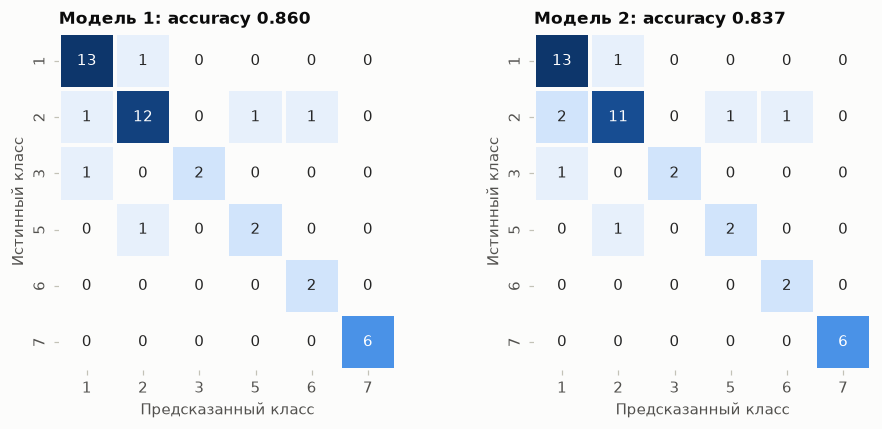

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(8.8, 4))
plot_confusion(axes[0], y_test, pred_base, f"Модель 1: accuracy {metrics_base['accuracy']:.3f}")
plot_confusion(axes[1], y_test, pred_clean, f"Модель 2: accuracy {metrics_clean['accuracy']:.3f}")
plt.tight_layout()
plt.show()

**Итог модели 2:** accuracy = **0.8372** (36 из 43) против **0.8605** (37 из 43) у модели 1 — на **2.3 п.п. ниже**, то есть ровно на одну тестовую запись: ещё одна запись класса 2 теперь классифицируется как класс 1. Balanced accuracy и macro-F1 тоже немного снизились (0.8325 и 0.8198). На этом тестовом множестве удаление выбросов модель не улучшило.

### 7.2. Все способы очистки на одном и том же тесте

Для полноты картины повторим эксперимент для каждого метода из п. 6b: выбросы ищутся и удаляются только в обучающем множестве, тест — тот же.

In [28]:
split_rows = []
for name, fn in {"Без удаления": None, **METHODS}.items():
    mask = np.zeros(len(X_train_r), dtype=bool) if fn is None else fn(X_train_r, y_train_r)
    model = make_model().fit(X_train_r[~mask], y_train_r[~mask])
    m, _ = evaluate(model, X_test, y_test)
    left = y_train_r[~mask].value_counts().reindex(class_total.index, fill_value=0)
    split_rows.append({"метод": name, "удалено из train": int(mask.sum()),
                       "осталось в train по классам (1 · 2 · 3 · 5 · 6 · 7)": " · ".join(map(str, left.values)), **m})
split_results = pd.DataFrame(split_rows).set_index("метод")
split_results.style.format({"accuracy": "{:.4f}", "balanced_accuracy": "{:.4f}", "f1_macro": "{:.4f}"})

,удалено из train,осталось в train по классам (1 · 2 · 3 · 5 · 6 · 7),accuracy,balanced_accuracy,f1_macro
метод,,,,,
Без удаления,0,55 · 61 · 14 · 10 · 7 · 23,0.8605,0.8437,0.8318
IQR (1.5·IQR),59,49 · 44 · 12 · 1 · 4 · 1,0.6047,0.5484,0.4833
Z-оценка (|z| > 3),13,55 · 56 · 13 · 7 · 6 · 20,0.7674,0.7270,0.7287
Isolation Forest,9,55 · 57 · 14 · 8 · 6 · 21,0.7674,0.6659,0.6824
LOF,9,55 · 60 · 14 · 5 · 6 · 21,0.7907,0.6929,0.7141
Isolation Forest по классам,11,52 · 58 · 13 · 9 · 6 · 21,0.8372,0.8325,0.8198


### 7.3. Проверка устойчивости: повторная кросс-валидация

В тесте всего 43 записи, одна ошибка меняет accuracy на 2.3 п.п., поэтому вывод по одному разбиению ненадёжен. Проверим на повторной стратифицированной кросс-валидации (5 фолдов × 10 повторов = 50 обучений на метод). Выбросы удаляются **внутри каждого обучающего фолда**, валидационный фолд не очищается.

In [29]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
cv_rows = []
for name, fn in {"Без удаления": None, **METHODS}.items():
    acc, bal = [], []
    for tr_idx, va_idx in cv.split(X, y):
        X_tr, y_tr = X.iloc[tr_idx].reset_index(drop=True), y.iloc[tr_idx].reset_index(drop=True)
        mask = np.zeros(len(X_tr), dtype=bool) if fn is None else fn(X_tr, y_tr)
        model = make_model().fit(X_tr[~mask], y_tr[~mask])
        pred = model.predict(X.iloc[va_idx])
        acc.append(accuracy_score(y.iloc[va_idx], pred))
        bal.append(balanced_accuracy_score(y.iloc[va_idx], pred))
    cv_rows.append({"метод": name, "accuracy (среднее)": np.mean(acc), "accuracy (std)": np.std(acc),
                    "balanced accuracy (среднее)": np.mean(bal)})
cv_results = pd.DataFrame(cv_rows).set_index("метод")
base_cv = cv_results.loc["Без удаления", "accuracy (среднее)"]
cv_results["Δ accuracy к базовой, п.п."] = (cv_results["accuracy (среднее)"] - base_cv) * 100
cv_results.style.format("{:.4f}", subset=["accuracy (среднее)", "accuracy (std)", "balanced accuracy (среднее)"]) \
    .format("{:+.1f}", subset=["Δ accuracy к базовой, п.п."])

,accuracy (среднее),accuracy (std),balanced accuracy (среднее),"Δ accuracy к базовой, п.п."
метод,,,,
Без удаления,0.7818,0.0572,0.7351,+0.0
IQR (1.5·IQR),0.5954,0.0555,0.4931,-18.6
Z-оценка (|z| > 3),0.7649,0.0593,0.6999,-1.7
Isolation Forest,0.7747,0.0544,0.7048,-0.7
LOF,0.7677,0.0576,0.7000,-1.4
Isolation Forest по классам,0.7880,0.0603,0.7420,+0.6


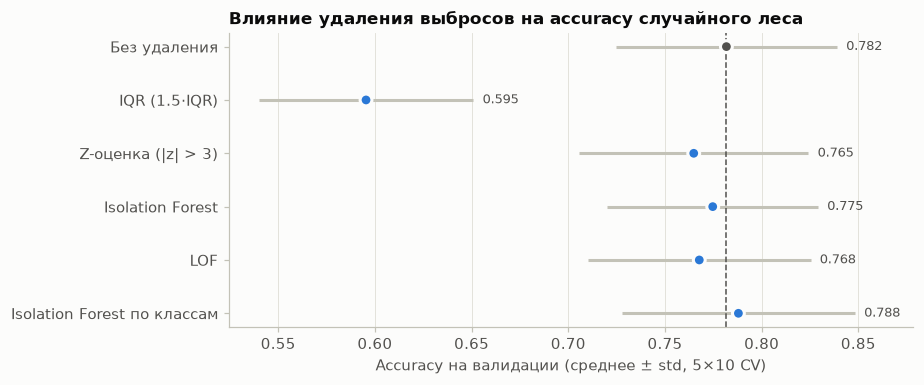

In [30]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
res = cv_results.iloc[::-1]
ypos = np.arange(len(res))
colors = [INK_2 if n == "Без удаления" else ACCENT for n in res.index]
ax.errorbar(res["accuracy (среднее)"], ypos, xerr=res["accuracy (std)"], fmt="none",
            ecolor=AXIS, elinewidth=2, capsize=0)
ax.scatter(res["accuracy (среднее)"], ypos, s=60, color=colors, zorder=3, edgecolor=SURFACE, linewidth=2)
ax.axvline(base_cv, color=INK_2, linewidth=1, linestyle="--")
for yi, v, s in zip(ypos, res["accuracy (среднее)"], res["accuracy (std)"]):
    ax.annotate(f"{v:.3f}", (v + s, yi), xytext=(6, 0), textcoords="offset points",
                ha="left", va="center", fontsize=8.5, color=INK_2)
ax.set_yticks(ypos, res.index)
ax.set_xlim(right=res["accuracy (среднее)"].add(res["accuracy (std)"]).max() + 0.03)
ax.set_xlabel("Accuracy на валидации (среднее ± std, 5×10 CV)")
ax.set_title("Влияние удаления выбросов на accuracy случайного леса")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Вывод по п. 7.2–7.3:**

- На фиксированном тесте **ни один способ очистки не превзошёл модель без удаления** (0.8605). IQR обрушил accuracy до 0.6047: в обучении осталось по 1 записи тары и фар. Z-оценка и глобальный Isolation Forest дали 0.7674, LOF — 0.7907; Isolation Forest по классам — 0.8372, ближе всего к базовой модели.
- Кросс-валидация подтверждает картину: без удаления — 0.782 ± 0.057; IQR — **−18.6 п.п.**; Z-оценка, Isolation Forest и LOF — от −0.7 до −1.7 п.п.; Isolation Forest по классам — **+0.6 п.п.** (0.788). Этот прирост в 10 раз меньше разброса между фолдами, то есть в пределах шума: аккуратная очистка не вредит, но и заметно не помогает.
- Почему так: **случайный лес устойчив к выбросам в признаках** — деревья делят выборку по порогам, и значение 6.21 вместо 1.5 просто окажется по ту же сторону порога. Зато на 170 записях каждая удалённая запись — потеря информации, особенно для классов из 7–14 записей.

### 7.4. Для сравнения: удаление выбросов из всего датасета до разбиения

Часто выбросы удаляют из всего датасета, а затем заново делят выборку. Покажем, почему такое сравнение вводит в заблуждение.

In [31]:
naive_rows = []
for name, fn in METHODS.items():
    mask = fn(X, y)
    X_c, y_c = X[~mask], y[~mask]
    Xa, Xb, ya, yb = train_test_split(X_c, y_c, test_size=TEST_SIZE, stratify=y_c, random_state=RANDOM_STATE)
    m, _ = evaluate(make_model().fit(Xa, ya), Xb, yb)
    lost = sorted(set(y.unique()) - set(y_c.unique()))
    naive_rows.append({"метод": name, "осталось записей": len(y_c), "размер теста": len(yb),
                       "потеряны классы": ", ".join(map(str, lost)) or "—", "accuracy": m["accuracy"]})
naive_results = pd.DataFrame(naive_rows).set_index("метод")
naive_results.style.format({"accuracy": "{:.4f}"})

,осталось записей,размер теста,потеряны классы,accuracy
метод,,,,
IQR (1.5·IQR),135,27,7,0.8519
Z-оценка (|z| > 3),193,39,—,0.8462
Isolation Forest,202,41,—,0.8049
LOF,202,41,—,0.8537
Isolation Forest по классам,200,40,—,0.8250


**Почему этот подход вводит в заблуждение.** Accuracy здесь выглядит «не хуже» (0.80–0.85), но:

- после IQR из данных **полностью исчез класс 7 (фары)**: такая модель вообще не умеет их распознавать, а accuracy 0.8519 посчитана на 27 записях, среди которых фар нет;
- тестовые множества во всех строках разные (27–41 запись вместо 43) и заранее очищены от трудных объектов, поэтому эти значения нельзя сравнивать ни между собой, ни с моделью 1;
- детектор выбросов «видел» тестовые данные — это утечка информации.

Корректное сравнение возможно только на одном и том же нетронутом тесте (п. 7.1–7.2) или на кросс-валидации с очисткой внутри обучающих фолдов (п. 7.3).

## 8. Выводы

### a. Какие преобразования сделаны с данными

1. Удалён 1 полный дубликат (214 → 213 записей), чтобы одна и та же запись не попала одновременно в train и test.
2. Выборка разделена стратифицированно: 170 записей в обучение и 43 в тест (80/20); тест зафиксирован и одинаков для обеих моделей.
3. Распределения исследованы через `sns.boxplot` и `sns.histplot(kde=True)` (замена устаревшего `sns.distplot`), нормальность проверена тестами Шапиро–Уилка и Д'Агостино–Пирсона и Q–Q графиками: нормально распределённых признаков нет.
4. Выбросы найдены пятью способами — IQR, Z-оценка, Isolation Forest, LOF и Isolation Forest внутри классов; для каждого рассчитан процент помеченных записей каждого класса.
5. Выбросы удалены методом Isolation Forest внутри класса **только из обучающего множества**: 11 записей (6.5 %), по классам — от 4.9 % до 14.3 %.

Масштабирование и преобразования признаков для случайного леса не применялись — деревьям они не нужны (`StandardScaler` используется только внутри LOF).

### b. Сравнение точности двух моделей

| Модель | Записей в обучении | Accuracy | Balanced accuracy | Macro-F1 |
|---|---|---|---|---|
| 1 — исходные данные | 170 | **0.8605** | 0.8437 | 0.8318 |
| 2 — без выбросов (Isolation Forest по классам) | 159 | **0.8372** | 0.8325 | 0.8198 |

Модель 2 ошиблась на одну запись больше (−2.3 п.п.). На кросс-валидации 5×10 картина обратная, но разница в пределах шума: 0.782 без удаления и 0.788 с удалением (+0.6 п.п. при разбросе около 6 п.п.). Грубая очистка по IQR снижает accuracy на 18.6 п.п. **Итог: для случайного леса на этом датасете удаление выбросов не даёт значимого прироста точности, а неудачный метод очистки сильно её ухудшает.**

### c. Мнение о необходимости исследования данных на выбросы

Исследовать данные на выбросы нужно **всегда**, а вот **удалять** их — только осознанно, понимая природу каждого случая.

**Плюсы исследования и обработки выбросов:**

- находит ошибки ввода, дубликаты и сбои измерений, которые иначе попадут в обучение;
- помогает понять структуру данных: здесь анализ «выбросов» показал, что `Ba`, `Mg`, `K` и `Al` — ключевые признаки редких классов;
- критично для моделей, чувствительных к выбросам: линейных моделей, kNN, SVM, кластеризации и любых методов на расстояниях и средних, а также для корректной работы `StandardScaler`;
- в регрессии снижает влияние экстремальных значений на функцию потерь (MSE).

**Минусы и риски:**

- «выброс» зависит от метода и порога: пять методов пометили от 11 до 78 записей и почти не совпали между собой;
- на маленьких несбалансированных данных удаление выбрасывает самые информативные объекты редких классов (IQR пометил 100 % фар);
- удаление выбросов из всего датасета до разбиения искажает оценку качества и создаёт утечку данных;
- в реальной эксплуатации нетипичные объекты всё равно придут на вход — модель должна уметь с ними работать;
- для деревьев и ансамблей на их основе выигрыш обычно минимален, что и подтвердил эксперимент.

**Практическая рекомендация:** сначала выяснить природу выброса — ошибка это или редкое, но реальное явление. Ошибки исправлять или удалять, реальные редкие значения оставлять. Для чувствительных моделей использовать мягкие методы вместо удаления: винзоризацию (ограничение значений квантилями), преобразование Йео–Джонсона (Бокс–Кокс здесь не подходит из-за нулевых значений), `RobustScaler` или модели, устойчивые к выбросам. Детектор выбросов обучать только на train и учитывать класс записи.